# Axe 8 : le graphe des secteurs qui « souffrent ensemble »

L'idée : deux secteurs sont **proches** si leurs défaillances **évoluent de la même façon** dans le temps (ils montent et baissent ensemble). On relie les secteurs proches et on obtient un **graphe**. On regarde ensuite quels groupes de secteurs se forment (communautés), quels secteurs sont au centre, et on en fait une carte.

C'est la même démarche que pour la carte des films du TP4 : **tableau → similarité → seuil → graphe → communautés → node2vec → carte 2D**. Le code commun aux graphes (axes 8 et 9) est dans `scripts/graphe_utils.py`.

### Lexique

| Terme | En clair |
|---|---|
| **Division NAF** | Un secteur d'activité à 2 chiffres (ex. `56` = restauration). Il y en a 88. |
| **Évolution sur 12 mois glissants** | Pour un mois donné : les défaillances des 12 derniers mois, comparées aux 12 mois d'avant. +20 % = 20 % de défaillances en plus sur un an. |
| **Corrélation de Pearson** | Mesure si deux courbes bougent ensemble de façon **linéaire**. Sensible aux valeurs extrêmes. (C'est aussi le cosinus de deux courbes centrées-réduites.) |
| **Corrélation de Spearman** | Pearson calculé sur les **rangs** : mesure si deux courbes montent et descendent ensemble, sans exiger une droite. **Robuste** aux valeurs extrêmes. |
| **Seuil** | La similarité minimale pour relier deux secteurs dans le graphe. |
| **Degré, intermédiarité, PageRank** | Trois façons de mesurer si un secteur est central : nombre de voisins, rôle de « pont » entre groupes, importance de ses voisins. |
| **Small world** | Un réseau où les voisins d'un nœud sont souvent voisins entre eux, tout en ayant des chemins courts. |
| **Communauté (Louvain)** | Un groupe de nœuds très reliés entre eux et peu reliés au reste. La **modularité** mesure si les groupes sont nets (au-delà de 0,3 : structure marquée). |
| **ARI** | Indice de Rand ajusté : compare deux découpages (1 = identiques, 0 = pas plus semblables que le hasard). |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Préparation des courbes | **Évolution sur 12 mois glissants**. Ça retire la taille du secteur et le creux d'août, et garde les crises. | Luka |
| Petits secteurs | On enlève les divisions avec **moins de 500 défaillances** au total (bruit) : on garde 62 divisions sur 84. | Luka |
| Coefficient de similarité | **Spearman** au lieu de Pearson. Pearson est gonflé par les valeurs extrêmes du Covid (section 3), la fiche de révision recommande alors Spearman. | Luka |
| Seuil | **0,60**, donné par la méthode du coude sur Spearman (section 4). Le seuil de 0,75 choisi au départ valait pour Pearson. | Luka |
| Nombre de communautés | Règle en 3 étapes sur 50 graines (section 8) : la résolution γ qui maximise la modularité moyenne, le nombre de communautés le plus fréquent à ce γ, et parmi ces graines le découpage de meilleure modularité. | Luka |

## 1. Chargement

In [1]:
import sys
sys.path.append("../../scripts")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from data_utils import NAF_DIVISIONS, NAF_SECTION_NOMS, NAF_SECTIONS, PROCESSED
import graphe_utils as gu

DASH = PROCESSED.parent / "dashboard"
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_colwidth", 70)

series = pd.read_parquet(DASH / "series_divisions_mois.parquet").loc["2008-01":"2026-10"]
total = series.sum().sort_values()
print(series.shape, "(mois × divisions) | divisions avec moins de 500 défaillances :", (total < 500).sum())

(226, 84) (mois × divisions) | divisions avec moins de 500 défaillances : 22


## 2. Préparation des courbes

In [2]:
MIN_DEFAILLANCES = 500
gardees = total[total >= MIN_DEFAILLANCES].index
evolution = gu.evolution_12_mois(series[gardees])
print("divisions gardées :", len(gardees), "| mois :", evolution.index[0], "→", evolution.index[-1], f"({len(evolution)} mois)")

nom = lambda d: NAF_DIVISIONS[d]
section_de = lambda d: next(l for l, (a, b) in NAF_SECTIONS.items() if a <= int(d) <= b)
exemple = ["41", "43", "47", "56", "62", "68"]
(100 * evolution[exemple].iloc[::12]).round(0).rename(columns=NAF_DIVISIONS)

divisions gardées : 62 | mois : 2009-12 → 2026-10 (203 mois)


naf_division,Construction de bâtiments,Travaux de construction spécialisés,Commerce de détail,Restauration,"Programmation, conseil informatique",Activités immobilières
mois,,,,,,
2009-12,14.0,19.0,14.0,13.0,27.0,28.0
2010-12,-12.0,-1.0,-3.0,1.0,-6.0,-20.0
2011-12,-8.0,-2.0,3.0,3.0,-6.0,0.0
2012-12,-3.0,1.0,1.0,6.0,11.0,6.0
2013-12,-0.0,2.0,5.0,6.0,-3.0,5.0
2014-12,0.0,0.0,-4.0,2.0,-7.0,-0.0
2015-12,1.0,-0.0,-1.0,9.0,-10.0,-3.0
2016-12,-5.0,-13.0,-6.0,-3.0,18.0,-0.0
2017-12,-12.0,-10.0,-4.0,-7.0,-1.0,-16.0


### Observations

- On garde **62 divisions** et **203 mois** d'évolution (décembre 2009 à octobre 2026 : il faut 24 mois d'historique pour calculer la première évolution).
- Dans les grands secteurs, on voit le même schéma : des variations faibles jusqu'en 2019, une forte baisse en 2020-2021 (les défaillances ont été gelées par les aides), puis une forte hausse en 2022-2023 (le rattrapage).

## 3. Quelle similarité : Pearson ou Spearman ?

Comme dans la fiche de révision (TP1, le café) : on calcule **les deux coefficients** et on regarde **l'écart**. Si **Pearson ≫ Spearman**, quelques points extrêmes portent la corrélation.

In [3]:
pearson = evolution.corr(method="pearson")
spearman = evolution.corr(method="spearman")
paires = pd.DataFrame({"pearson": gu.triangle(pearson), "spearman": gu.triangle(spearman)})
paires["écart"] = paires["pearson"] - paires["spearman"]
print("paires de secteurs :", len(paires), "| corrélation entre les deux matrices :",
      round(paires["pearson"].corr(paires["spearman"]), 3))
paires.describe().round(3)

paires de secteurs : 1891 | corrélation entre les deux matrices : 0.868


,pearson,spearman,écart
count,1891.000,1891.000,1891.000
mean,0.539,0.425,0.115
std,0.209,0.184,0.104
min,-0.223,-0.191,-0.319
25%,0.391,0.299,0.045
50%,0.561,0.426,0.111
75%,0.701,0.562,0.183
max,0.978,0.893,0.478


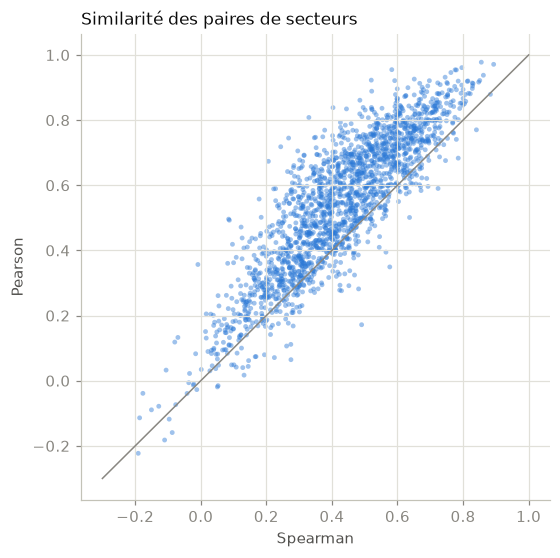

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(paires["spearman"], paires["pearson"], s=10, color=gu.BLEU, alpha=0.45, edgecolors="none")
ax.plot([-0.3, 1], [-0.3, 1], color=gu.GRIS, lw=1)
ax.set_xlabel("Spearman"); ax.set_ylabel("Pearson")
ax.set_title("Similarité des paires de secteurs", loc="left", fontsize=11, color=gu.TITRE)
plt.show()

In [5]:
# Les paires où les deux coefficients s'écartent le plus
ecarts = paires.reindex(paires["écart"].abs().sort_values(ascending=False).index).head(8).reset_index()
ecarts.columns = ["a", "b", "pearson", "spearman", "écart"]
ecarts.assign(**{"secteur a": ecarts["a"].map(nom), "secteur b": ecarts["b"].map(nom)})[
    ["secteur a", "secteur b", "pearson", "spearman", "écart"]].round(3)

,secteur a,secteur b,pearson,spearman,écart
0,"Produits informatiques, électroniques et optiques",Industries alimentaires,0.808,0.330,0.478
1,Fabrication de machines et équipements,Industries alimentaires,0.745,0.268,0.477
2,Industrie automobile,Industries alimentaires,0.718,0.244,0.474
3,"Activités sportives, récréatives et de loisirs",Commerce et réparation automobile,0.674,0.206,0.467
4,Réparation d'ordinateurs et de biens personnels,Travaux de construction spécialisés,0.838,0.403,0.435
5,Fabrication de boissons,Activités liées à l'emploi,0.496,0.085,0.411
6,"Produits informatiques, électroniques et optiques",Édition,0.705,0.296,0.410
7,"Collecte et traitement des déchets, récupération",Activités liées à l'emploi,0.493,0.087,0.406


### Observations

- Les deux coefficients vont dans le même sens (corrélation de 0,87 entre les deux matrices), mais **Pearson est presque toujours au-dessus de Spearman** : +0,12 en moyenne, jusqu'à +0,48. Sur le nuage, presque toutes les paires sont au-dessus de la diagonale.
- D'après la fiche, **Pearson ≫ Spearman** veut dire que **quelques points extrêmes portent la corrélation**. Exemple : produits informatiques ↔ industries alimentaires (0,81 avec Pearson, 0,33 avec Spearman).

### Vérification : est-ce le Covid ?

Hypothèse : pendant le Covid puis le rattrapage, presque tous les secteurs ont plongé puis bondi **en même temps**. Ces mois extrêmes, communs à tous, pourraient gonfler Pearson. On recalcule les deux coefficients **sans les années 2020 à 2024** (l'évolution sur 12 mois de ces années est touchée par la crise).

In [6]:
periodes = {
    "toute la période": evolution,
    "sans 2020-2024": evolution[(evolution.index < "2020-01") | (evolution.index > "2024-12")],
    "avant 2020 seulement": evolution[evolution.index < "2020-01"],
}
pd.DataFrame({
    nom_p: {"mois": len(e),
            "Pearson médian": gu.triangle(e.corr()).median(),
            "Spearman médian": gu.triangle(e.corr("spearman")).median(),
            "écart moyen (Pearson - Spearman)": (gu.triangle(e.corr()) - gu.triangle(e.corr("spearman"))).mean()}
    for nom_p, e in periodes.items()
}).T.round(3)

,mois,Pearson médian,Spearman médian,écart moyen (Pearson - Spearman)
toute la période,203.0,0.561,0.426,0.115
sans 2020-2024,143.0,0.122,0.100,0.024
avant 2020 seulement,121.0,0.091,0.072,0.023


### Observations

- L'hypothèse est **confirmée** : sans les années 2020 à 2024, l'écart entre Pearson et Spearman disparaît presque (+0,02 au lieu de +0,12).
- Mais on apprend surtout autre chose : **sans le Covid, les secteurs ne se ressemblent presque plus**. La similarité médiane tombe de 0,56 à 0,12 (Pearson) et de 0,43 à 0,10 (Spearman). Avant 2020, les défaillances de chaque secteur variaient surtout de façon propre à chacun.
- Le graphe parle donc surtout de **la façon dont les secteurs ont vécu la crise du Covid puis le rattrapage**. C'est pour ça qu'on garde toute la période, mais avec **Spearman**, moins sensible à l'ampleur des pics.

## 4. Choisir le seuil (méthode du coude, sur Spearman)

On fait varier le seuil et on trace le nombre de secteurs gardés, d'arêtes, et la modularité. Le coude est repéré automatiquement (méthode *Kneedle* : le point le plus éloigné de la droite entre les deux extrémités de la courbe).

coudes : {'nœuds gardés': 0.6, 'arêtes': 0.61}


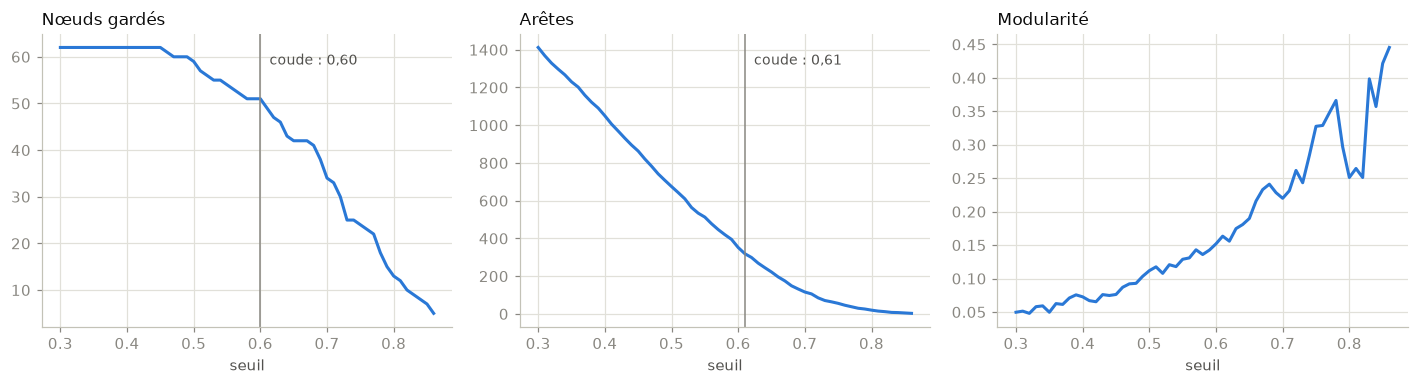

,nœuds gardés,arêtes,composantes,communautés,modularité
seuil,,,,,
0.50,59,675,1,3,0.112
0.51,57,643,1,3,0.117
0.52,56,610,1,4,0.108
0.53,55,564,1,4,0.121
0.54,55,534,1,5,0.118
0.55,54,513,1,4,0.129
0.56,53,478,1,4,0.131
0.57,52,447,1,4,0.143
0.58,51,420,1,5,0.136


In [7]:
S = spearman
courbes = gu.courbe_seuils(S, np.round(np.arange(0.30, 0.861, 0.01), 2))
coudes = {m: gu.coude(courbes.index, courbes[m]) for m in ["nœuds gardés", "arêtes"]}
print("coudes :", coudes)
gu.tracer_coudes(courbes, coudes)
courbes.loc[0.50:0.70].round(3)

### Observations

- La méthode du coude donne **0,60** pour les secteurs gardés et **0,61** pour les arêtes : cette fois, les deux courbes sont d'accord.
- À 0,60, on garde **51 secteurs** et **352 arêtes**, en un seul morceau.

## 5. Le graphe retenu (Spearman, seuil 0,60)

In [8]:
SEUIL = 0.60
G = gu.construire_graphe(S, SEUIL)
isoles = [d for d in S.index if d not in G]
nx.set_node_attributes(G, {d: nom(d) for d in G}, "nom")
print(G, "| composantes :", nx.number_connected_components(G), "| densité :", round(nx.density(G), 3))
pd.DataFrame({"secteur": [nom(d) for d in isoles], "défaillances": [int(total[d]) for d in isoles],
              "meilleure similarité": [S[d].drop(d).max() for d in isoles]}, index=isoles
            ).sort_values("meilleure similarité", ascending=False).round(3)

Graph with 51 nodes and 352 edges | composantes : 1 | densité : 0.276


,secteur,défaillances,meilleure similarité
38,"Collecte et traitement des déchets, récupération",1455,0.576
02,"Sylviculture, exploitation forestière",2781,0.564
03,Pêche et aquaculture,647,0.559
15,Industrie du cuir et de la chaussure,510,0.549
11,Fabrication de boissons,612,0.529
20,Industrie chimique,811,0.518
79,"Agences de voyage, voyagistes",1801,0.503
78,Activités liées à l'emploi,1657,0.501
93,"Activités sportives, récréatives et de loisirs",8522,0.498
35,"Électricité, gaz, vapeur et air conditionné",821,0.461


### Observations

- Le graphe a **51 secteurs** et **352 arêtes**, avec une densité de 0,28 (plus de 1 paire sur 4 est reliée).
- **11 secteurs** restent isolés. La plupart sont petits, mais il y a aussi les **activités sportives et de loisirs** (8 522 défaillances) et la **location** (6 092), qui évoluent à part.

## 6. Est-ce un réseau « small world » ?

In [9]:
tableau, sigma = gu.small_world(G)
print("sigma =", round(sigma, 2))
tableau.round(3)

sigma = 1.84


,notre graphe,graphes aléatoires (20)
clustering moyen,0.584,0.279
plus court chemin moyen,1.976,1.738
diamètre,5.000,3.000


### Observations

- Le clustering moyen vaut **0,58**, contre **0,28** pour des graphes aléatoires de même taille, pour des chemins à peine plus longs (**1,98** étape contre 1,74).
- **σ = 1,84** (> 1) : le graphe a la propriété **small world**.

## 7. Les secteurs centraux

In [10]:
cent = gu.centralites(G)
cent.insert(0, "secteur", [nom(d) for d in cent.index])
cent.insert(1, "section", [section_de(d) for d in cent.index])
cent["défaillances"] = [int(total[d]) for d in cent.index]
cent.sort_values("degré", ascending=False).head(10).round(3)

,secteur,section,degré,intermédiarité,pagerank,défaillances
46,Commerce de gros,G,31,0.052,0.041,49365
47,Commerce de détail,G,30,0.047,0.040,126840
41,Construction de bâtiments,F,28,0.038,0.036,29487
71,"Architecture, ingénierie, contrôle technique",M,27,0.041,0.037,16893
45,Commerce et réparation automobile,G,26,0.053,0.034,35862
56,Restauration,I,26,0.027,0.034,114163
59,"Cinéma, vidéo, télévision, musique enregistrée",J,25,0.108,0.038,4192
64,Services financiers,K,25,0.059,0.033,12115
49,Transports terrestres,H,24,0.054,0.033,30401
82,Soutien administratif aux entreprises,N,23,0.018,0.029,10296


In [11]:
cent.sort_values("intermédiarité", ascending=False).head(10).round(3)

,secteur,section,degré,intermédiarité,pagerank,défaillances
59,"Cinéma, vidéo, télévision, musique enregistrée",J,25,0.108,0.038,4192
62,"Programmation, conseil informatique",J,22,0.061,0.031,12545
64,Services financiers,K,25,0.059,0.033,12115
49,Transports terrestres,H,24,0.054,0.033,30401
45,Commerce et réparation automobile,G,26,0.053,0.034,35862
46,Commerce de gros,G,31,0.052,0.041,49365
88,Action sociale sans hébergement,Q,10,0.047,0.018,3495
47,Commerce de détail,G,30,0.047,0.040,126840
73,Publicité et études de marché,M,10,0.042,0.017,7880
71,"Architecture, ingénierie, contrôle technique",M,27,0.041,0.037,16893


In [12]:
cent[["degré", "intermédiarité", "pagerank", "défaillances"]].corr(method="spearman").round(2)

,degré,intermédiarité,pagerank,défaillances
degré,1.00,0.82,0.99,0.72
intermédiarité,0.82,1.00,0.86,0.64
pagerank,0.99,0.86,1.00,0.71
défaillances,0.72,0.64,0.71,1.00


### Observations

- Les secteurs les plus reliés sont le **commerce de gros** (31 voisins), le **commerce de détail** (30), la **construction de bâtiments** (28) et l'**ingénierie** (27).
- Le secteur le plus « pont » est le **cinéma, vidéo, télévision, musique** (intermédiarité 0,108, deux fois plus que le suivant), alors qu'il est petit (4 192 défaillances). L'**action sociale** et la **publicité** jouent aussi un rôle de pont avec seulement 10 voisins.
- Comme avant, les centralités sont liées à la taille du secteur (Spearman 0,64 à 0,72) : les grands secteurs ont des courbes plus régulières, plus faciles à rapprocher des autres.

## 8. Les communautés (Louvain) : combien en garder ?

Avec Louvain, on ne fixe pas le nombre de communautés : l'algorithme le trouve en maximisant la **modularité**. Le seul réglage est la **résolution γ** (plus γ est haut, plus il fait de petits groupes). Et Louvain n'est pas déterministe : le résultat change avec la graine aléatoire.

On choisit donc avec une **règle en 3 étapes**, appliquée sur 50 graines pour chaque γ :
1. **γ** = celui qui donne la **meilleure modularité moyenne** ;
2. **nombre de communautés** = celui qui revient **le plus souvent** à ce γ ;
3. parmi les graines qui donnent ce nombre, on garde le **découpage de meilleure modularité**.

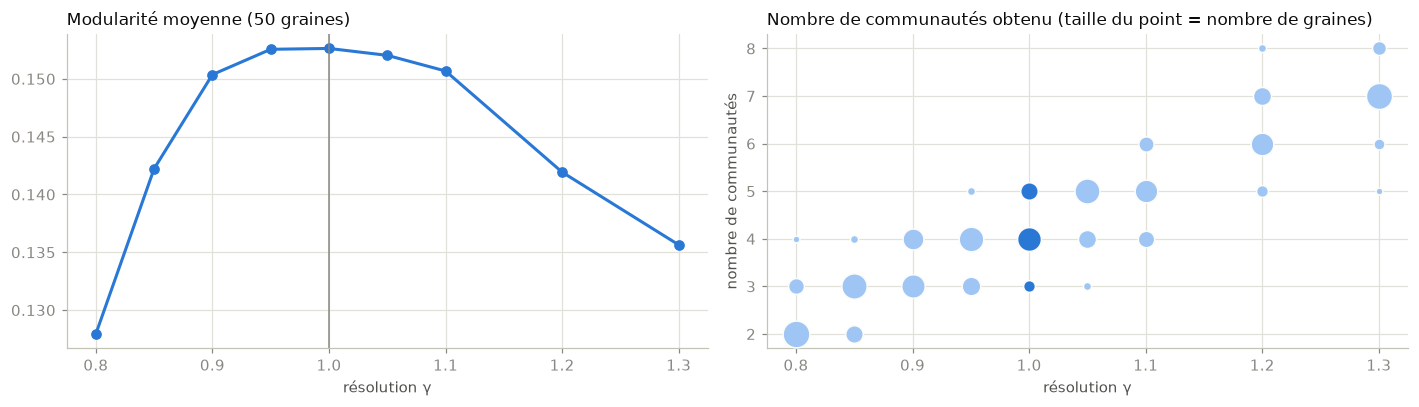

règle : γ = 1.0 | 4 communautés | modularité du découpage retenu : 0.163


,modularité moyenne,nombre le plus fréquent,part des graines avec ce nombre,répartition du nombre,ARI moyen entre graines
résolution,,,,,
0.80,0.128,2,0.74,"{2: 37, 3: 12, 4: 1}",0.316
0.85,0.142,3,0.66,"{2: 15, 3: 33, 4: 2}",0.394
0.90,0.150,3,0.56,"{3: 28, 4: 22}",0.446
0.95,0.153,4,0.62,"{3: 17, 4: 31, 5: 2}",0.465
1.00,0.153,4,0.58,"{3: 6, 4: 29, 5: 15}",0.511
1.05,0.152,5,0.64,"{3: 2, 4: 16, 5: 32}",0.528
1.10,0.151,5,0.52,"{4: 13, 5: 26, 6: 11}",0.513
1.20,0.142,6,0.52,"{5: 6, 6: 26, 7: 16, 8: 2}",0.510
1.30,0.136,7,0.70,"{5: 1, 6: 5, 7: 35, 8: 9}",0.488


In [13]:
tableau_gamma, partitions = gu.balayage_resolution(G, [0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.3])
gamma, nombre, communautes, communaute, q = gu.regle_communautes(tableau_gamma, partitions)
gu.tracer_balayage(tableau_gamma, gamma)
print(f"règle : γ = {gamma} | {nombre} communautés | modularité du découpage retenu : {q:.3f}")
tableau_gamma.round(3)

### Observations

- La modularité moyenne forme un **plateau** autour de γ = 1 : 0,153 pour γ = 0,95 et 1, puis 0,152 pour 1,05. Elle reste **sous 0,3** partout : d'après la fiche, la structure en communautés est **peu marquée**.
- À γ = 1, Louvain trouve **4 communautés** dans 29 graines sur 50, 5 dans 15 graines, 3 dans 6 graines. La règle retient donc **4 communautés**, avec le découpage de meilleure modularité (**0,163**).
- Les découpages restent assez différents d'une graine à l'autre (ARI d'environ 0,5) : ces communautés sont à lire comme des **tendances**, pas comme des familles bien séparées.

In [14]:
# Le découpage retenu par la règle
cent["communauté"] = pd.Series(communaute)
print(f"{len(communautes)} communautés, modularité {q:.3f}")
for i, c in enumerate(communautes, 1):
    top = sorted(c, key=lambda d: -total[d])
    print(f"\n{i}. ({len(c)} secteurs) " + " · ".join(nom(d) for d in top))

4 communautés, modularité 0.163

1. (16 secteurs) Activités immobilières · Transports terrestres · Construction de bâtiments · Architecture, ingénierie, contrôle technique · Programmation, conseil informatique · Culture, production animale, chasse · Fabrication de produits métalliques · Santé humaine · Auxiliaires de services financiers et d'assurance · Imprimerie et reproduction · Entreposage et services auxiliaires des transports · Services d'information · Organisations associatives · Produits en caoutchouc et en plastique · Produits informatiques, électroniques et optiques · Fabrication d'équipements électriques

2. (15 secteurs) Travaux de construction spécialisés · Restauration · Commerce de gros · Services financiers · Soutien administratif aux entreprises · Enquêtes et sécurité · Autres activités spécialisées, scientifiques et techniques · Hébergement · Réparation et installation de machines · Activités créatives, artistiques et de spectacle · Travail du bois · Fabrication de me

In [15]:
pd.crosstab(cent["section"].map(lambda l: f"{l} {NAF_SECTION_NOMS[l]}"), cent["communauté"], margins=True)

communauté,1,2,3,4,All
section,,,,,
A Agriculture,1,0,0,0,1
C Industrie manufacturière,5,5,2,3,15
F Construction,1,2,0,0,3
G Commerce,0,1,2,0,3
H Transports,2,0,1,0,3
"I Hébergement, restauration",0,2,0,0,2
"J Information, communication",2,0,1,2,5
"K Finance, assurance",1,1,0,0,2
L Immobilier,1,0,0,0,1


### Observations

- Les **4 communautés** (16, 15, 14 et 6 secteurs) mélangent des sections NAF différentes.
- **Communauté 1** : immobilier, transports, construction de bâtiments, ingénierie, informatique, agriculture, santé.
- **Communauté 2** : construction spécialisée, restauration, commerce de gros, services financiers, soutien administratif, sécurité, hébergement.
- **Communauté 3** : commerce de détail, réparation automobile, services personnels, alimentaire, enseignement, services aux bâtiments, publicité, culture.
- **Communauté 4** : conseil de gestion, édition, télécoms, industrie automobile et machines, autres industries.

## 9. Comment chaque communauté a-t-elle vécu les crises ?

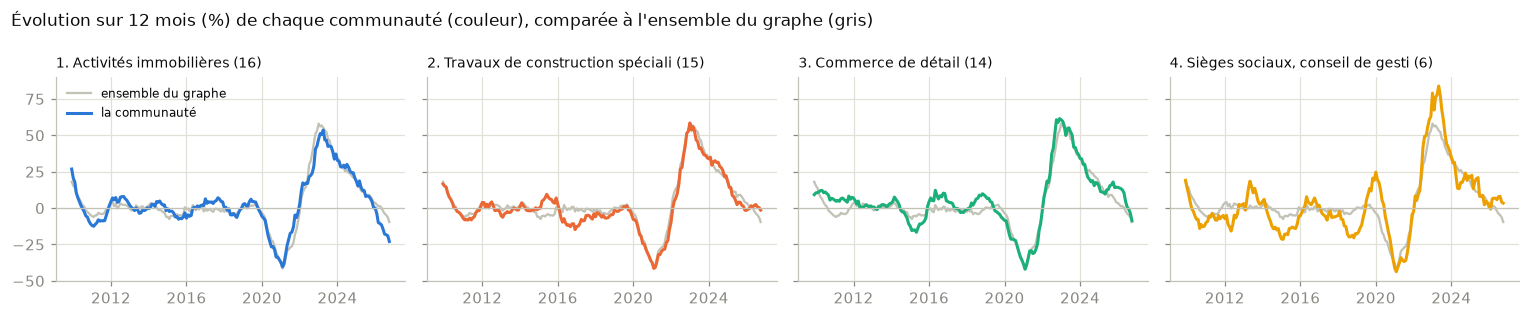

In [16]:
nom_comm = lambda c: nom(max(c, key=lambda d: total[d]))
gu.tracer_evolution_communautes(evolution, communautes, nom_comm,
    "Évolution sur 12 mois (%) de chaque communauté (couleur), comparée à l'ensemble du graphe (gris)")

In [17]:
# Les chiffres clés de chaque communauté : creux pendant le Covid, pic du rattrapage (et sa date)
lignes = []
for i, c in enumerate(communautes, 1):
    e = 100 * evolution[sorted(c)].mean(axis=1)
    lignes.append({"communauté": i, "secteurs": len(c), "secteur principal": nom_comm(c),
                   "creux Covid (%)": e.loc["2020-01":"2021-12"].min(),
                   "pic du rattrapage (%)": e.loc["2022-01":"2024-12"].max(),
                   "date du pic": e.loc["2022-01":"2024-12"].idxmax()})
resume = pd.DataFrame(lignes).set_index("communauté")
resume.round(0)

,secteurs,secteur principal,creux Covid (%),pic du rattrapage (%),date du pic
communauté,,,,,
1,16,Activités immobilières,-40.0,54.0,2023-04
2,15,Travaux de construction spécialisés,-41.0,59.0,2023-01
3,14,Commerce de détail,-42.0,62.0,2022-12
4,6,"Sièges sociaux, conseil de gestion",-44.0,84.0,2023-05


### Observations

- Toutes les communautés ont vécu le Covid de la même façon : un creux entre **−40 % et −44 %**.
- Les différences sont au **rattrapage**. La communauté 4 (conseil de gestion, édition, industrie) monte le plus haut, **+84 %**, et le plus tard (mai 2023). La communauté 1 (immobilier, transports, bâtiment) monte le moins (**+54 %**). La communauté 3 (commerce de détail, services personnels) atteint son pic la première (décembre 2022).

## 10. Visualisation du graphe

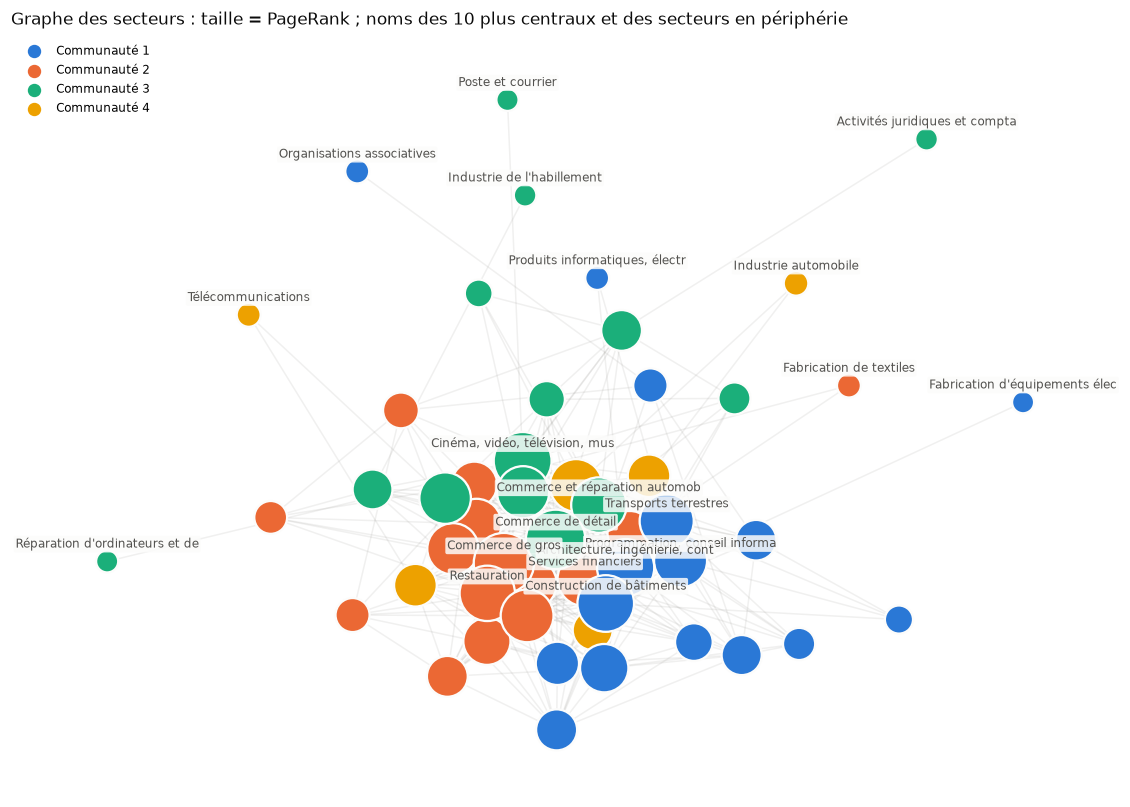

In [18]:
pos = nx.spring_layout(G, weight="weight", seed=0, k=0.6)
taille = 60 + 1500 * cent["pagerank"] / cent["pagerank"].max()
a_nommer = set(cent["pagerank"].nlargest(10).index) | set(cent.index[cent["degré"] <= 2])
gu.dessiner_graphe(G, pos, communaute, taille, a_nommer, nom,
                   "Graphe des secteurs : taille = PageRank ; noms des 10 plus centraux et des secteurs en périphérie")

## 11. node2vec : une carte des secteurs

Comme au TP4 : marches aléatoires sur le graphe, puis Word2Vec apprend un vecteur (8 dimensions) par secteur, puis t-SNE en 2D. Réglages du TP4 (10 marches de 40 pas, p = q = 1), avec une perplexité de 10 car il y a peu de secteurs.

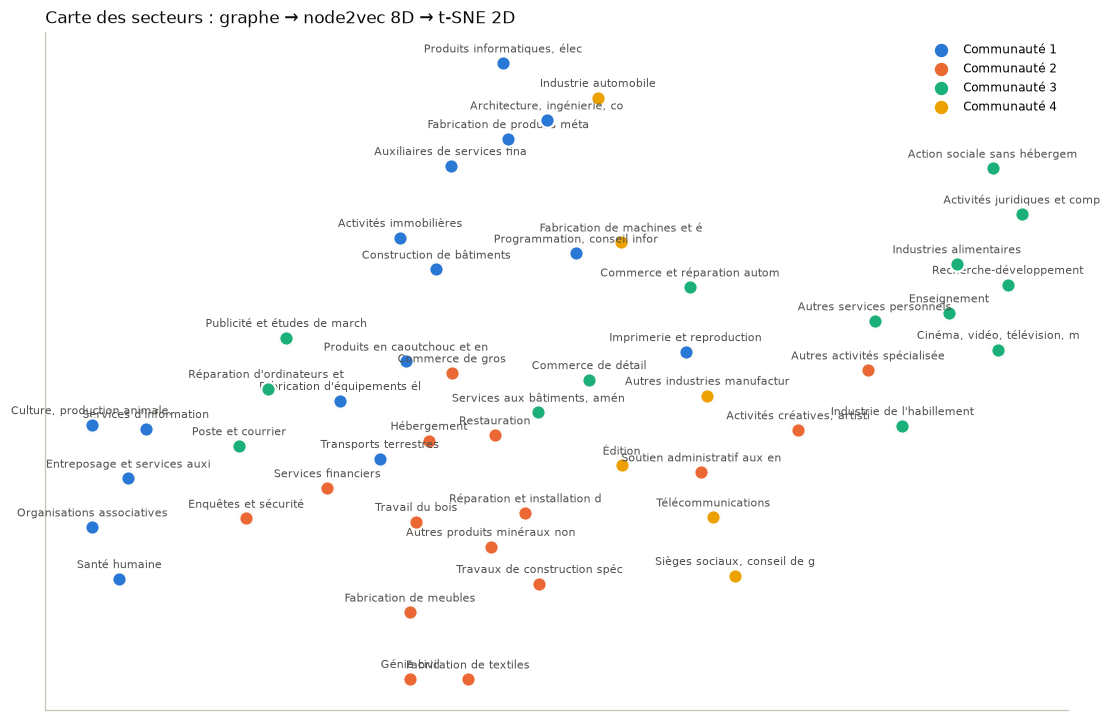

voisins sur la carte dans la même communauté : 0.63


In [19]:
noeuds, vecteurs, carte = gu.node2vec_tsne(G, perplexite=10)
fig, ax = plt.subplots(figsize=(12, 8))
for i, d in enumerate(noeuds):
    ax.scatter(*carte[i], s=90, color=gu.COULEURS[(communaute[d] - 1) % len(gu.COULEURS)],
               edgecolors="#fcfcfb", linewidths=1.5, zorder=3)
    ax.annotate(nom(d)[:28], carte[i], xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7, color=gu.ENCRE)
for i in range(len(communautes)):
    ax.scatter([], [], s=60, color=gu.COULEURS[i % len(gu.COULEURS)], label=f"Communauté {i + 1}")
ax.legend(frameon=False, fontsize=8)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Carte des secteurs : graphe → node2vec 8D → t-SNE 2D", loc="left", fontsize=11, color=gu.TITRE)
plt.show()
print("voisins sur la carte dans la même communauté :",
      round(gu.accord_voisins(carte, [communaute[d] for d in noeuds]), 2))

### Observations

- Sur la carte node2vec + t-SNE, **63 %** des 3 plus proches voisins de chaque secteur sont dans la même communauté : les communautés se voient sur la carte, mais elles se mélangent en partie, ce qui va avec une modularité faible.

## 12. Export pour le dashboard

In [20]:
noeuds_df = cent.copy()
noeuds_df.index.name = "division"
noeuds_df["x_graphe"] = [pos[d][0] for d in noeuds_df.index]
noeuds_df["y_graphe"] = [pos[d][1] for d in noeuds_df.index]
noeuds_df = noeuds_df.join(pd.DataFrame(carte, index=noeuds, columns=["x_carte", "y_carte"])).reset_index()
aretes_df = pd.DataFrame([(u, v, d["weight"]) for u, v, d in G.edges(data=True)], columns=["source", "cible", "similarite"])
evo_comm = pd.DataFrame({f"Communauté {i}": evolution[sorted(c)].mean(axis=1) for i, c in enumerate(communautes, 1)})
evo_comm["Ensemble"] = evolution[list(G)].mean(axis=1)

noeuds_df.to_parquet(DASH / "graphe_secteurs_noeuds.parquet", index=False)
aretes_df.to_parquet(DASH / "graphe_secteurs_aretes.parquet", index=False)
evo_comm.to_parquet(DASH / "graphe_secteurs_evolution.parquet")
resume.reset_index().to_parquet(DASH / "graphe_secteurs_communautes.parquet", index=False)
print(len(noeuds_df), "secteurs |", len(aretes_df), "arêtes |", evo_comm.shape)

51 secteurs | 352 arêtes | (203, 5)
